# Nodal market fundamentals on the WSCC 9-bus network

This notebook states the clearing of a nodal energy market at its simplest and clears it three times on the WSCC 9-bus case. Example 1 is one market with no binding line. Example 2 rates line 6-7 at 40 MW, and the binding line separates the nodal prices. Example 3 clears the same market as two balancing authority areas, each with its own power balance, and reports each area's production cost and what its load pays. The closing sandbox clears two markets independently on the same network, each enforcing only its own lines.

Each clearing is one period, energy only, on a lossless DC network, with offers at cost.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/pdockery/wscc9-illustrative-model/blob/main/101_fundamentals.ipynb)

In [1]:
#@title ▶ Run me first: Colab setup (installs packages, fetches the library)
# On Google Colab this installs the packages Colab lacks and downloads the
# library modules into lib/. Run locally, it walks up from the working
# directory to the folder that holds lib/seams_engine.py.
import pathlib
import subprocess
import sys

LIB_MODULES = (
    "seams_engine", "wscc9_model", "ieee9_network", "nodal_plot",
    "wscc9_figures", "seam_views", "etag", "risk", "revenue_allocation",
    "atc", "bilateral", "footprints", "intertie", "lab_types",
)


def _sh(cmd: str) -> None:
    print("$", cmd)
    subprocess.run(cmd, shell=True, check=True)


if "google.colab" in sys.modules:
    _sh("pip install -q pypsa pandapower pycirclize")
    _base = "https://raw.githubusercontent.com/pdockery/wscc9-illustrative-model/main/lib"
    _lib = pathlib.Path("lib").resolve()
    _lib.mkdir(exist_ok=True)
    for _m in LIB_MODULES:
        _sh(f"wget -q {_base}/{_m}.py -O {_lib / (_m + '.py')}")
    print("Colab setup complete.")
else:
    _r = pathlib.Path.cwd().resolve()
    while not (_r / "lib" / "seams_engine.py").exists() and _r != _r.parent:
        _r = _r.parent
    _lib = _r / "lib"
    print("Local run: modules from the repository's lib/")
if str(_lib) not in sys.path:
    sys.path.insert(0, str(_lib))

Local run: modules from the repository's lib/


In [2]:
import json
import logging
import pathlib
import urllib.request
import warnings
from typing import Any

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

import footprints as fpmod
import seam_views as sv
import wscc9_figures as figs
import wscc9_model as wm
from footprints import Footprints
from nodal_plot import compute_ptdf_flows, plot_combined_letter
from seams_engine import (
    EngineResult,
    MarketEngine,
    PTDFData,
    compute_ptdf,
    physical_flows,
    solve_engine_dispatch,
    solve_engine_transfers,
    susceptance_widths,
    to_supply_demand,
)
from wscc9_model import BUS_COLORS, CENTER_BUS, COORDS, RING_ORDER

warnings.filterwarnings("ignore")
for _name in ("pypsa", "ieee9_network"):
    logging.getLogger(_name).setLevel(logging.ERROR)
pd.set_option("display.width", 160)
# Inline figures draw no suptitle, panel title or legend, and no file is written.
sv.configure(strip_inline=True, save_enabled=False)
TOL = 1e-6   # MW and $/MWh tolerance on an identity

## The case

The case is the WSCC 3-machine, 9-bus system, built from pandapower's `case9` and solved with bus 1 as the slack. Three units offer at cost, and three buses carry load. The figure shows the case before any clearing. On the ring, each unit is drawn at its full capacity and its offer, and each load is drawn to the height of the dearest offer. On the network, each line is labelled with its rating and drawn with a width proportional to its susceptance. The last table gives each bus's shift factor on each line, with the lines as rows.

,bus,cost,p_nom
unit,,,
gen_slack_0,1,50.0,250.0
gen_0,2,35.0,300.0
gen_1,3,20.0,170.0


bus,5,7,9
load (MW),90.0,100.0,125.0


,line_0,line_1,line_2,line_3,line_4,line_5,line_6,line_7,line_8
ends,1-4,4-5,5-6,3-6,6-7,7-8,8-2,8-9,9-4
rating (MW),250.0,250.0,150.0,300.0,150.0,250.0,250.0,250.0,250.0


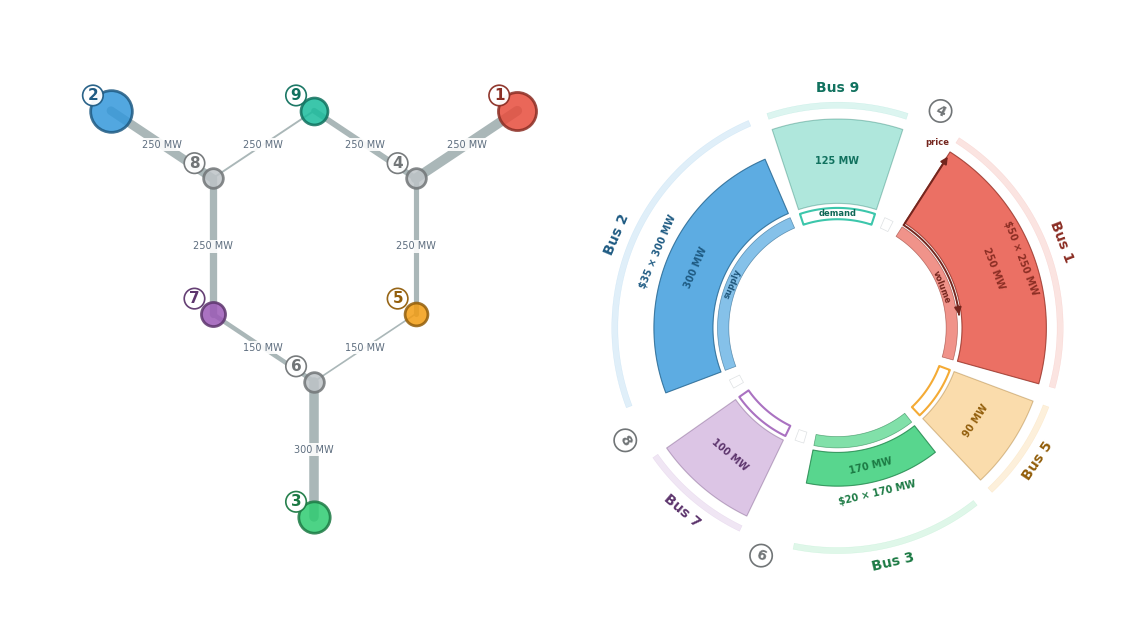

,bus 1,bus 2,bus 3,bus 4,bus 5,bus 6,bus 7,bus 8,bus 9
line_0 (1-4),0.0,-1.000,-1.000,-1.0,-1.000,-1.000,-1.000,-1.000,-1.000
line_1 (4-5),0.0,-0.361,-0.615,-0.0,-0.865,-0.615,-0.467,-0.361,-0.125
line_2 (5-6),0.0,-0.361,-0.615,-0.0,0.135,-0.615,-0.467,-0.361,-0.125
line_3 (3-6),0.0,0.000,1.000,-0.0,0.000,0.000,-0.000,0.000,0.000
line_4 (6-7),0.0,-0.361,0.385,0.0,0.135,0.385,-0.467,-0.361,-0.125
line_5 (7-8),0.0,-0.361,0.385,-0.0,0.135,0.385,0.533,-0.361,-0.125
line_6 (8-2),0.0,-1.000,0.000,0.0,0.000,0.000,0.000,0.000,0.000
line_7 (8-9),0.0,0.639,0.385,0.0,0.135,0.385,0.533,0.639,-0.125
line_8 (9-4),0.0,0.639,0.385,0.0,0.135,0.385,0.533,0.639,0.875


In [3]:
FLEET = {g: dict(s) for g, s in wm.DEFAULT_GEN_FLEET.items()}   # {unit: {bus, cost $/MWh, p_nom MW}}
LOADS = dict(wm.DEFAULT_LOADS)                                   # {bus: MW}
NET0 = wm.build_network()
PT0 = compute_ptdf(NET0, slack_bus="1")


def configuration_figure(net: Any, pt: PTDFData, fleet: dict, loads: dict) -> None:
    """The case with no clearing: capacity at its offer, load at the dearest offer, line ratings."""
    sup: dict = {}
    for g, s in fleet.items():
        cap = float(s["p_nom"])
        sup.setdefault(str(s["bus"]), []).append(
            {"unit_id": g, "price": float(s["cost"]), "volume": cap, "capacity": cap,
             "accepted_volume": cap})
    top = max(float(s["cost"]) for s in fleet.values())
    fig, (ax_net, _ax_ring) = plot_combined_letter(
        net, sup, {str(b): float(v) for b, v in loads.items() if v > 0},
        bus_colors=dict(BUS_COLORS), bus_lmps=dict.fromkeys(pt.buses, top), show_bus_price=False,
        network_show_lmp=False, line_flows=dict.fromkeys(pt.lines, 0.0),
        line_widths=susceptance_widths(pt), flows=[], lmp_line=False, all_buses=pt.buses,
        sector_order=RING_ORDER, bus_coords=COORDS, center_bus=CENTER_BUS,
        annotate_roles=True, axis_key=True, title_left="", title_right="")
    for m, (b0, b1) in zip(pt.lines, pt.line_buses, strict=True):   # each line's rating at its midpoint
        (x0, y0), (x1, y1) = COORDS[b0], COORDS[b1]
        ax_net.text((x0 + x1) / 2, (y0 + y1) / 2, f"{pt.s_nom[pt.line_idx[m]]:.0f} MW",
                    fontsize=7, ha="center", va="center", color="#5D6D7E",
                    bbox={"fc": "white", "ec": "none", "alpha": 0.9, "pad": 1.0}, zorder=6)
    plt.show()


display(pd.DataFrame(FLEET).T.rename_axis("unit"))
display(pd.Series(LOADS, name="load (MW)").rename_axis("bus").to_frame().T)
display(pd.DataFrame({"ends": [f"{a}-{b}" for a, b in PT0.line_buses],
                      "rating (MW)": PT0.s_nom}, index=PT0.lines).T)
configuration_figure(NET0, PT0, FLEET, LOADS)
wm.sf_table(PT0)

## Formulation

The market clears a bid-based economic dispatch on a DC network. It chooses each unit's dispatch to serve the load at the least offered cost, within each unit's capacity and each line's rating, and shift factors map each bus's net injection to each line's flow.

| Symbol | Code | Definition |
|---|---|---|
| $n$, $\mathcal N$ | `pt.buses` | a bus, and the set of buses |
| $m$, $\mathcal M_{\mathrm{act}}$ | `pt.lines`, `activated` | a line, and the lines whose ratings the market enforces |
| $a$, $\mathcal A$, $\mathcal N_a$, $a(n)$ | `AREAS` | an area, the set of areas, the buses of area $a$, and the area that holds bus $n$ |
| $i$, $\mathrm{bus}(i)$, $c_i$, $\bar g_i$ | `FLEET` | a unit, its bus, its offer and its capacity |
| $g_i$ | `res.dispatch` | the dispatch of unit $i$ |
| $d_n$ | `LOADS` | the load at bus $n$ |
| $SF_{n,m}$ | `wm.sf_table(pt)` | the shift factor of bus $n$ on line $m$ |
| $F_m$, $\bar F_m$ | `res.flow_own`, `pt.s_nom` | the flow on line $m$, and its rating |
| $t_{ab}$ | `res.transfers` | the scheduled transfer from area $a$ to area $b$ |
| $\hat\lambda_a$ | `res.area_prices` | the energy price of area $a$ |
| $\lambda_n$ | `res.lmp` | the nodal price at bus $n$ |
| $\mu_m$ | `res.line_dual` | the shadow price of line $m$'s rating, signed |
| $C_a$, $L_a$ | `cost_and_payment` | area $a$'s production cost, and what its load pays |
| $M$, $F^M_m$, $F^s_m$ | `MARKETS`, `physical_flows` | a market of the sandbox, its own flow on line $m$, and the sum of the markets' flows |

$$\begin{aligned}
\min_{g,\,t}\ \ &\sum_i c_i\,g_i\\
\text{s.t.}\ \ &\sum_{i:\,\mathrm{bus}(i)\in\mathcal N_a}g_i-\sum_{n\in\mathcal N_a}d_n=\sum_b\big(t_{ab}-t_{ba}\big),\quad a\in\mathcal A && [\hat\lambda_a]\\
&-\bar F_m\le F_m\le\bar F_m,\quad m\in\mathcal M_{\mathrm{act}} && [\mu_m]\\
&0\le g_i\le\bar g_i,\quad t_{ab}\ge 0.
\end{aligned}\qquad(1)$$

*In words.* The market minimizes the offered cost $\sum_i c_i\,g_i$ of its units' dispatch. In each area $a$, the generation at the area's buses less the load there equals the area's net scheduled transfer $\sum_b(t_{ab}-t_{ba})$ (dual $\hat\lambda_a$, the area's energy price). On each activated line, the flow $F_m$ stays within the rating $\bar F_m$ (dual $\mu_m$, the line's shadow price). Each unit runs between zero and its capacity $\bar g_i$, and each transfer is non-negative.

Examples 1 and 2 have one area, so the balance reads $\sum_i g_i=\sum_n d_n$ and carries no transfer. Example 3 has two areas, joined by one interface with no limit on the transfer, so (1) carries no interface constraint and no interface dual. Every line is activated in the three examples.

$$F_m=\sum_{n\in\mathcal N}SF_{n,m}\Big(\sum_{i:\,\mathrm{bus}(i)=n}g_i-d_n\Big).\qquad(2)$$

*In words.* The flow on line $m$, $F_m$, is the shift factor $SF_{n,m}$ of each bus on that line times the bus's net injection, its generation less its load, summed over the buses.

Note that a transfer does not enter (2). The flow follows the dispatch, and the transfer records each area's net export.

$$\lambda_n=\hat\lambda_{a(n)}+\sum_{m\in\mathcal M_{\mathrm{act}}}SF_{n,m}\,\mu_m.\qquad(3)$$

*In words.* The nodal price at bus $n$, $\lambda_n$, is the energy price $\hat\lambda_{a(n)}$ of the area that holds the bus, plus the bus's shift factor $SF_{n,m}$ on each activated line times that line's shadow price $\mu_m$.

A line that does not bind has a shadow price of zero, so with no binding line every bus of an area has the area's energy price.

The EDAM technical description derives the nodal price from the shadow prices of the binding constraints in the same way (`caiso_edam_techdesc`, p. 26). Its formula divides the energy price by each node's loss penalty factor and subtracts the shadow-price term. This notebook is lossless, so every loss penalty factor is 1, and $\mu_m$ is signed, so (3) adds the shadow-price term.

$$C_a=\sum_{i:\,\mathrm{bus}(i)\in\mathcal N_a}c_i\,g_i,\qquad L_a=\sum_{n\in\mathcal N_a}\lambda_n\,d_n.\qquad(4)$$

*In words.* Area $a$'s production cost, $C_a$, is the offer $c_i$ times the dispatch $g_i$ of each unit in the area, summed over the area's units. What the area's load pays, $L_a$, is the nodal price $\lambda_n$ times the load $d_n$ at each of the area's buses, summed over those buses.

**Two markets on one network.** The sandbox clears two markets. Each market $M$ clears (1) alone, with one area, its own footprint's units and load, and its own activated lines. Its own flow $F^M_m$ is (2) over its own units and load, and (4) gives its production cost and what its load pays.

$$F^s_m=\sum_M F^M_m.\qquad(5)$$

*In words.* The flow the markets produce together on line $m$, $F^s_m$, is the sum over the markets of each market's own flow $F^M_m$.

Note that each market holds only its own flow within a line's rating, so neither market holds $F^s_m$ within it.

**Notebook-local helpers.** `clear` builds the network with the stated ratings and clears (1), with one area or with the areas it is given. `cost_and_payment` evaluates (4) over a set of buses. `figure` draws a clearing as the network and nodal dispatch figure, and `show_binding` prints each binding line, and `report` prints the nodal prices, the binding lines, and the production cost and load payment of each area.

In [4]:
def clear(ratings: dict, areas: dict | None = None, fleet: dict | None = None,
          loads: dict | None = None) -> tuple[Any, PTDFData, MarketEngine, EngineResult]:
    """The clearing of eq. (1), with ``ratings`` ({line: MW}) over the case ratings.

    With ``areas`` None the market has one area. With ``areas`` as {area: buses},
    each area has its own power balance, and the two are joined by an unlimited
    interface.
    """
    net = wm.build_network(ratings)
    pt = compute_ptdf(net, slack_bus="1")
    eng = wm.make_engine("Market", pt.buses, gen_fleet=fleet or FLEET, loads=loads or LOADS)
    if areas is None:
        res = solve_engine_dispatch(pt, eng)
    else:
        res = solve_engine_transfers(pt, eng, areas, {tuple(sorted(areas)): None})
    return net, pt, eng, res


def cost_and_payment(eng: MarketEngine, res: EngineResult, buses: list) -> dict:
    """Eq. (4) over ``buses``: generation, load, production cost and load payment."""
    units = [g for g, s in eng.gens.items() if str(s["bus"]) in buses]
    return {
        "generation (MW)": sum(res.dispatch[g] for g in units),
        "load (MW)": sum(float(eng.loads.get(b, 0.0)) for b in buses),
        "production cost ($/h)": sum(float(eng.gens[g]["cost"]) * res.dispatch[g] for g in units),
        "load pays ($/h)": sum(res.lmp[b] * float(eng.loads.get(b, 0.0)) for b in buses),
    }


def figure(net: Any, pt: PTDFData, fp: Footprints, eng: MarketEngine, res: EngineResult,
           highlight: str | None = None, prices: dict | None = None) -> None:
    """The network and nodal dispatch figure.

    With ``highlight``, the other footprints are grayed; ``prices`` replaces the
    clearing's own nodal prices on the ring.
    """
    fig = figs.footprint_figure(net, pt, fp, eng, res, highlight=highlight, bus_lmps=prices,
                                title_left="", title_right="")
    sv.strip(fig)
    plt.show()


def show_binding(pt: PTDFData, res: EngineResult, label: str = "Binding lines") -> None:
    """Each binding line with its flow, its rating and its signed shadow price, or none."""
    rows = {f"{m} ({'-'.join(pt.line_buses[pt.line_idx[m]])})":
            {"flow (MW)": res.flow_own[m], "rating (MW)": pt.s_nom[pt.line_idx[m]],
             "shadow price ($/MWh)": mu}
            for m, mu in res.line_dual.items() if abs(mu) > TOL}
    if not rows:
        print(f"{label}: none")
        return
    print(f"{label}:")
    display(pd.DataFrame(rows).T.round(2))


def report(pt: PTDFData, eng: MarketEngine, res: EngineResult, areas: dict) -> pd.DataFrame:
    """The nodal prices and the binding lines, printed, and eq. (4) by area, returned."""
    print("Nodal prices ($/MWh):")
    display(pd.Series({b: res.lmp[b] for b in pt.buses}, name="LMP").round(2).to_frame().T)
    show_binding(pt, res)
    table = pd.DataFrame({a: cost_and_payment(eng, res, list(b)) for a, b in areas.items()}).T
    if len(areas) > 1:
        table.loc["total"] = table.sum()
    print("Production cost and load payment, eq. (4):")
    display(table.round(1))
    return table

## Example 1. One market, no binding line

Every line carries its case rating, and the market has one area. The \$20 unit at bus 3 is expected to run at its 170 MW capacity, and the \$35 unit at bus 2 to serve the other 145 MW. No line is expected to bind, so by (3) every bus prices at the \$35 offer.

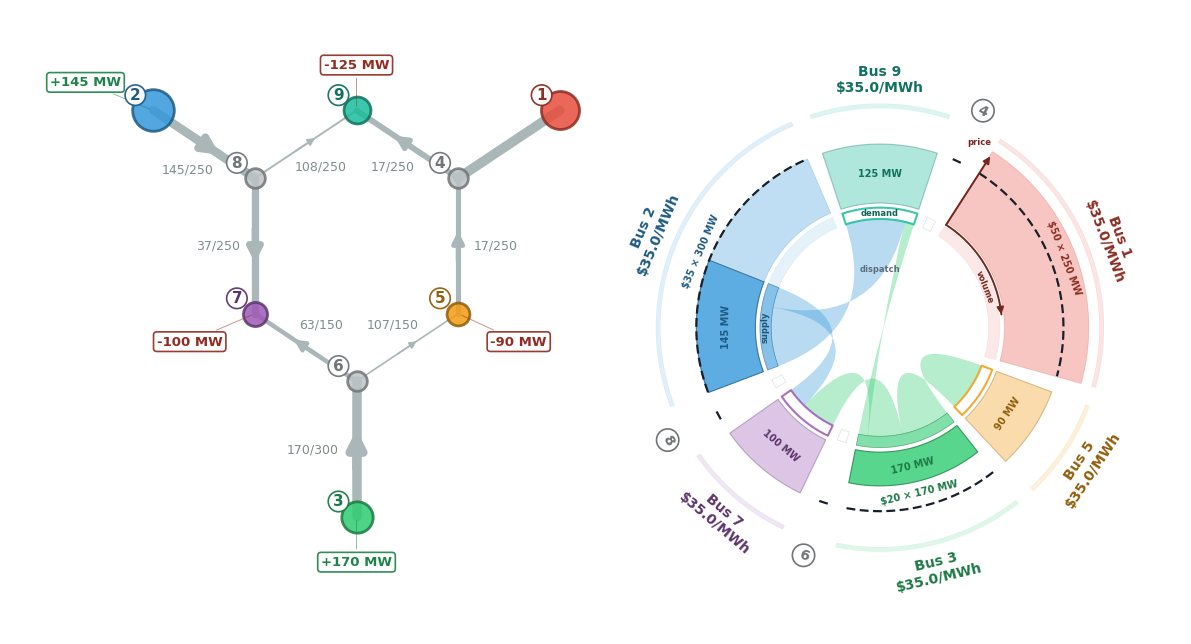

dispatch (MW):

{'gen_slack_0': 0.0, 'gen_0': 145.0, 'gen_1': 170.0}

flow on line_4, 6-7 (MW):

63.2

Nodal prices ($/MWh):

,1,2,3,4,5,6,7,8,9
LMP,35.0,35.0,35.0,35.0,35.0,35.0,35.0,35.0,35.0


Binding lines: none

Production cost and load payment, eq. (4):

,generation (MW),load (MW),production cost ($/h),load pays ($/h)
Market,315.0,315.0,8475.0,11025.0


In [5]:
ALL = {"Market": [str(b) for b in PT0.buses]}
NET1, PT1, ENG1, RES1 = clear({})
FP1 = fpmod.make(PT1, ALL, {"Market": "#5D6D7E"})
figure(NET1, PT1, FP1, ENG1, RES1)
print("dispatch (MW):", {g: round(x, 1) for g, x in RES1.dispatch.items()})
print("flow on line_4, 6-7 (MW):", round(RES1.flow_own["line_4"], 1))
TAB1 = report(PT1, ENG1, RES1, ALL)

No line binds, and every bus prices at \$35/MWh, the offer of the unit at bus 2. The \$20 unit at bus 3 runs at its 170 MW capacity, the \$35 unit at bus 2 runs 145 MW, and the \$50 unit at bus 1 is idle. The production cost is \$8,475/h, and load pays \$11,025/h, 315 MW at \$35/MWh. The dispatch places 63.2 MW on line 6-7, against its 150 MW rating.

## Example 2. One market, line 6-7 at 40 MW

Line 6-7, `line_4`, is rated 40 MW, below the flow Example 1 places on it. The limit is expected to bind. By (3), each bus's price is then the energy price plus its shift factor on line 6-7 times the line's shadow price, and the production cost rises above Example 1's.

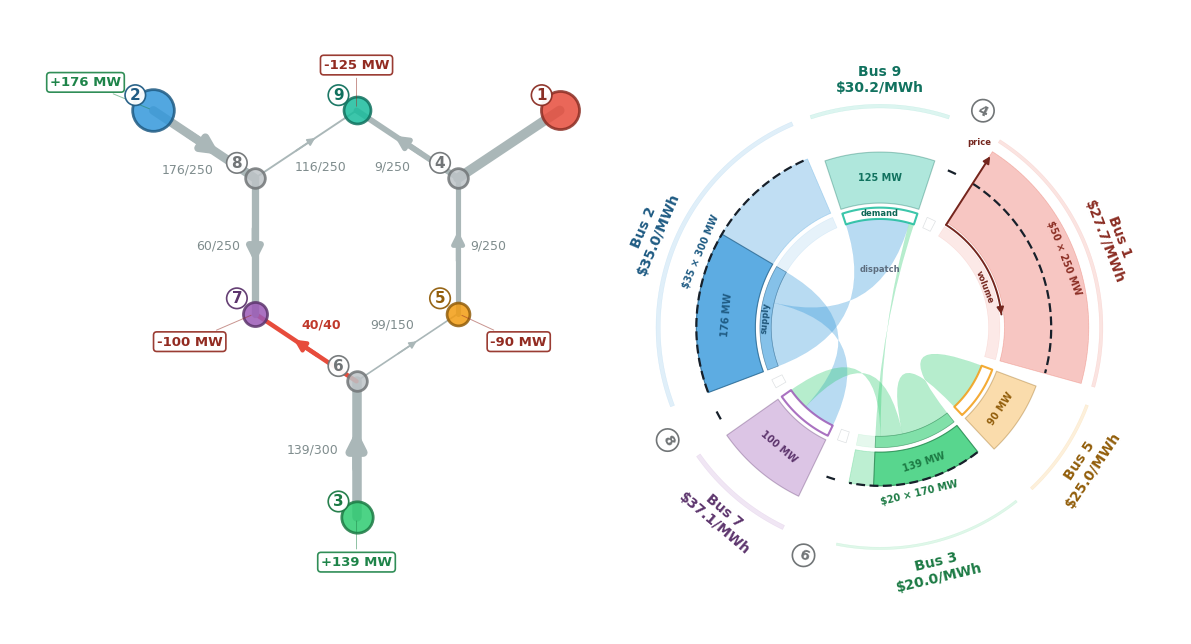

dispatch (MW):

{'gen_slack_0': 0.0, 'gen_0': 176.1, 'gen_1': 138.9}

energy price, the price at the slack bus ($/MWh):

27.74

Nodal prices ($/MWh):

,1,2,3,4,5,6,7,8,9
LMP,27.74,35.0,20.0,27.74,25.02,20.0,37.13,35.0,30.25


Binding lines:

,flow (MW),rating (MW),shadow price ($/MWh)
line_4 (6-7),40.0,40.0,-20.1


Production cost and load payment, eq. (4):

,generation (MW),load (MW),production cost ($/h),load pays ($/h)
Market,315.0,315.0,8941.0,9745.1


In [6]:
NET2, PT2, ENG2, RES2 = clear({"line_4": 40.0})
FP2 = fpmod.make(PT2, ALL, {"Market": "#5D6D7E"})
figure(NET2, PT2, FP2, ENG2, RES2)
print("dispatch (MW):", {g: round(x, 1) for g, x in RES2.dispatch.items()})
print("energy price, the price at the slack bus ($/MWh):", round(RES2.energy_price, 2))
TAB2 = report(PT2, ENG2, RES2, ALL)

Line 6-7 binds at 40 MW with a shadow price of $-\$20.10$/MWh. The \$20 unit at bus 3 falls to 138.9 MW and the \$35 unit at bus 2 rises to 176.1 MW, so the production cost rises by \$466/h to \$8,941/h. The energy price, the price at the slack bus 1, is \$27.74/MWh. Buses 3 and 6 price at the \$20 offer and buses 2 and 8 at the \$35 offer. The bus-7 load behind the line prices at \$37.13/MWh, the energy price plus its shift factor on line 6-7, $-0.467$, times the line's shadow price. Load pays \$9,745/h, \$1,280/h less than in Example 1, because the 215 MW of load at buses 5 and 9 prices below \$35/MWh and only the 100 MW at bus 7 prices above it.

In [7]:
# Example 2 against the repository's golden values, and eq. (3) at every bus.
GOLDEN_URL = ("https://raw.githubusercontent.com/pdockery/wscc9-illustrative-model/"
              "main/tests/golden/golden.json")


def load_golden() -> dict[str, Any]:
    """The 9-bus golden values: the repository's file, or its copy on GitHub on Colab."""
    here = pathlib.Path.cwd().resolve()
    for folder in (here, *here.parents):
        path = folder / "tests" / "golden" / "golden.json"
        if path.exists():
            return json.loads(path.read_text(encoding="utf-8"))
    with urllib.request.urlopen(GOLDEN_URL, timeout=30) as resp:  # noqa: S310  # a fixed https URL
        return json.loads(resp.read().decode("utf-8"))


GOLDEN_RTOL = 1e-6   # relative, against a golden value, with a floor of 1 on the scale
G = load_golden()["line4_unified"]
for b in PT2.buses:
    assert abs(RES2.lmp[b] - G[f"res.lmp.{b}"]) <= GOLDEN_RTOL * max(1.0, abs(G[f"res.lmp.{b}"])), b
    sf = {m: PT2.ptdf[PT2.line_idx[m], PT2.bus_idx[b]] for m in PT2.lines}
    assert abs(RES2.lmp[b] - RES2.energy_price
               - sum(sf[m] * RES2.line_dual[m] for m in PT2.lines)) <= TOL, b
assert abs(RES2.line_dual["line_4"] - G["res.line_dual.line_4"]) <= (
    GOLDEN_RTOL * max(1.0, abs(G["res.line_dual.line_4"])))
assert abs(RES2.total_cost - TAB2.loc["Market", "production cost ($/h)"]) <= TOL
print("Example 2 matches the golden values, and eq. (3) holds at every bus.")

Example 2 matches the golden values, and eq. (3) holds at every bus.

## Example 3. Two balancing authority areas, line 6-7 at 40 MW

The market of Example 2 now carries two areas, BA A at buses 2, 3, 6, 7 and 8 and BA B at buses 1, 4, 5 and 9, each with its own power balance. The two balances are joined by an unlimited interface. The dispatch and the nodal prices are expected to equal Example 2's, because an unlimited interface gives the two areas one energy price. The example adds each area's production cost, what its load pays, and the transfer between the two areas.

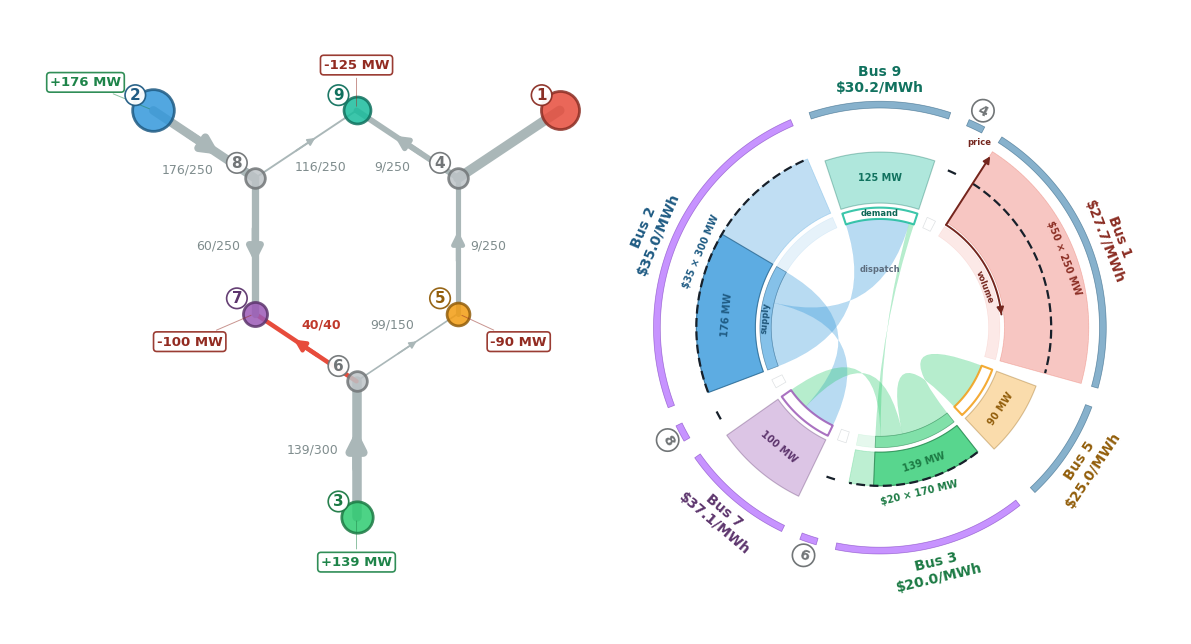

dispatch (MW):

{'gen_slack_0': 0.0, 'gen_0': 176.1, 'gen_1': 138.9}

area energy prices ($/MWh):

{'BA A': 27.74, 'BA B': 27.74}

transfer, BA A -> BA B (MW):

215.0

... (2 outputs left out)

Binding lines:

,flow (MW),rating (MW),shadow price ($/MWh)
line_4 (6-7),40.0,40.0,-20.1


Production cost and load payment, eq. (4):

,generation (MW),load (MW),production cost ($/h),load pays ($/h)
BA A,315.0,100.0,8941.0,3712.6
BA B,0.0,215.0,0.0,6032.5
total,315.0,315.0,8941.0,9745.1


In [8]:
AREAS = {"BA A": ["2", "8", "7", "6", "3"], "BA B": ["1", "9", "4", "5"]}
NET3, PT3, ENG3, RES3 = clear({"line_4": 40.0}, areas=AREAS)
FP3 = fpmod.make(PT3, AREAS, {"BA A": "#993AFF", "BA B": "#2471A3"})
figure(NET3, PT3, FP3, ENG3, RES3)
print("dispatch (MW):", {g: round(x, 1) for g, x in RES3.dispatch.items()})
print("area energy prices ($/MWh):", {a: round(v, 2) for a, v in RES3.area_prices.items()})
print("transfer, BA A -> BA B (MW):", round(RES3.transfers[("BA A", "BA B")], 1))
TAB3 = report(PT3, ENG3, RES3, AREAS)
for g in RES2.dispatch:
    assert abs(RES3.dispatch[g] - RES2.dispatch[g]) <= TOL, g
for b in PT3.buses:
    assert abs(RES3.lmp[b] - RES2.lmp[b]) <= TOL, b

The dispatch, the nodal prices and the shadow price on line 6-7 are Example 2's, and both areas' energy prices are \$27.74/MWh. Both dispatched units sit in BA A, so BA A carries the whole production cost of \$8,941/h and transfers 215 MW to BA B, whose \$50 unit at bus 1 is idle. BA A's load, 100 MW at bus 7, pays \$3,712.6/h. BA B's load, 215 MW at buses 5 and 9, pays \$6,032.5/h.

## Sandbox. Two markets on one network

The sandbox clears Market A and Market B independently on the same network. Each market serves its own load from its own units, with one area, and enforces the ratings of the lines `ACTIVATED` names for it. As configured, the footprints are Example 3's areas, `line_4` is rated 40 MW, and each market activates the lines at its own buses and one intertie: Market A line 5-6 and Market B line 8-9.

The cell draws each market's clearing with the other market grayed, and then the two clearings together, each line carrying the flow of (5) and drawn red where that flow exceeds the line's rating. It then prints the nodal prices, each bus priced by its own market, each market's binding lines, eq. (4) for each market beside the one-market clearing of the same knobs, and the flow of (5). Edit the knobs and rerun the cell. A case in which a market cannot serve its load within its units and its activated ratings has no solution, and the clearing raises.

In [9]:
# -- EDIT -- the sandbox ---------------------------------------------------------
SB_RATINGS = {"line_4": 40.0}          # {line: MW} over the case ratings; line_4 is 6-7
SB_FLEET = {g: dict(s) for g, s in wm.DEFAULT_GEN_FLEET.items()}   # {unit: {bus, cost, p_nom}}
SB_LOADS = dict(wm.DEFAULT_LOADS)      # {bus: MW}
MARKETS = {"Market A": ["2", "8", "7", "6", "3"],   # {market: footprint buses}
           "Market B": ["1", "9", "4", "5"]}
ACTIVATED = {"Market A": ["line_2", "line_3", "line_4", "line_5", "line_6"],   # lines each enforces
             "Market B": ["line_0", "line_1", "line_7", "line_8"]}
MARKET_COLORS = {"Market A": "#993AFF", "Market B": "#2471A3"}
# ---------------------------------------------------------------------------------

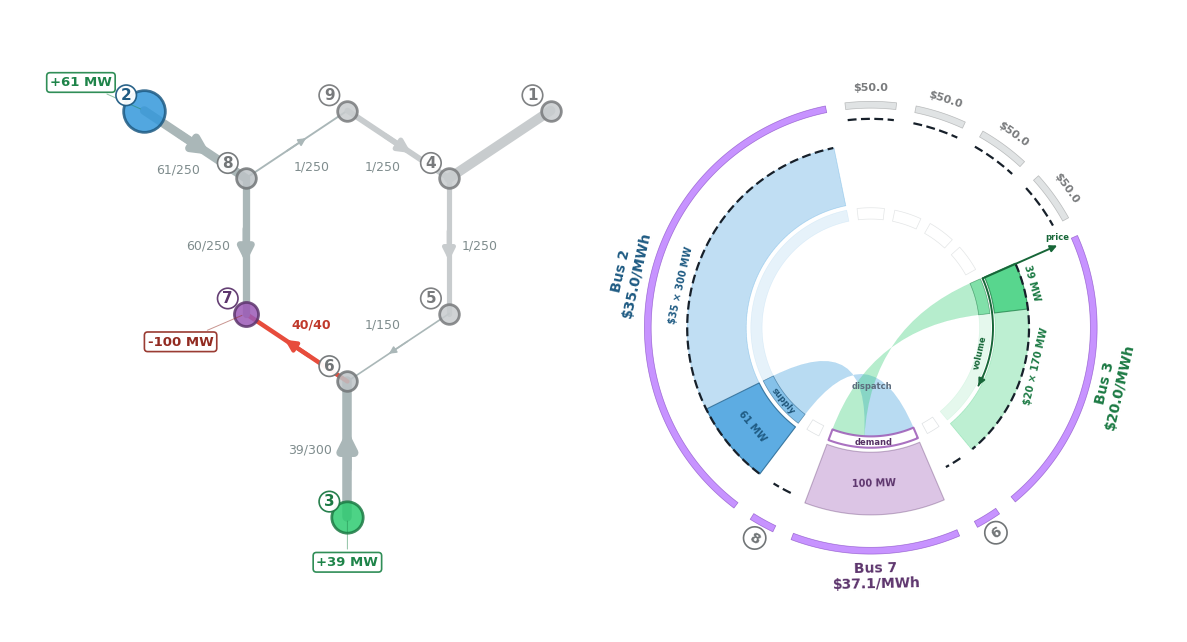

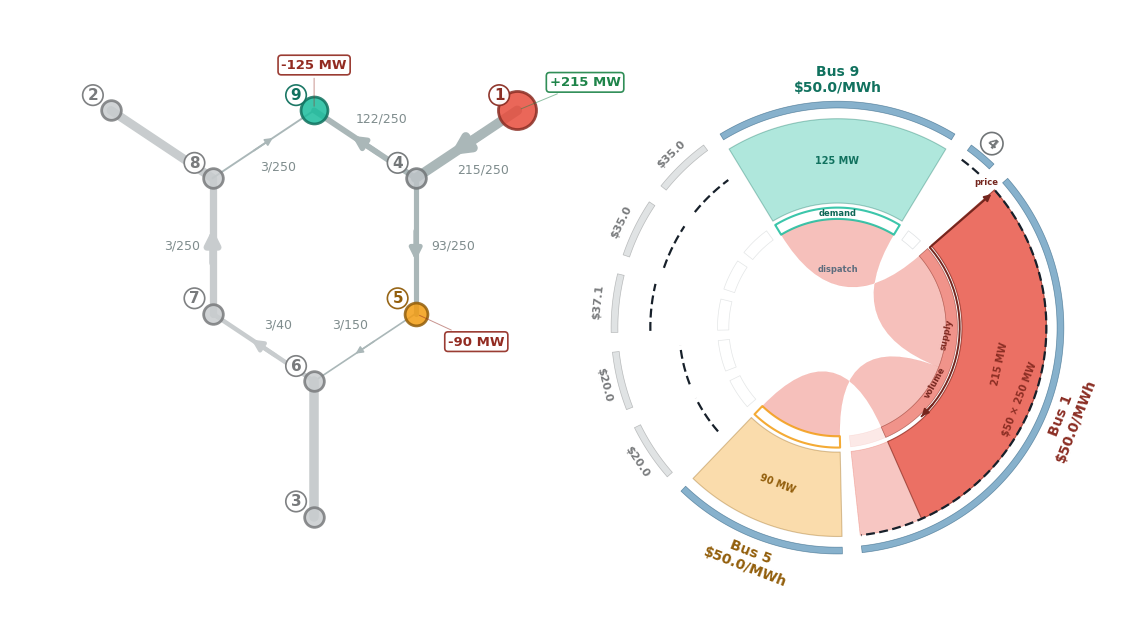

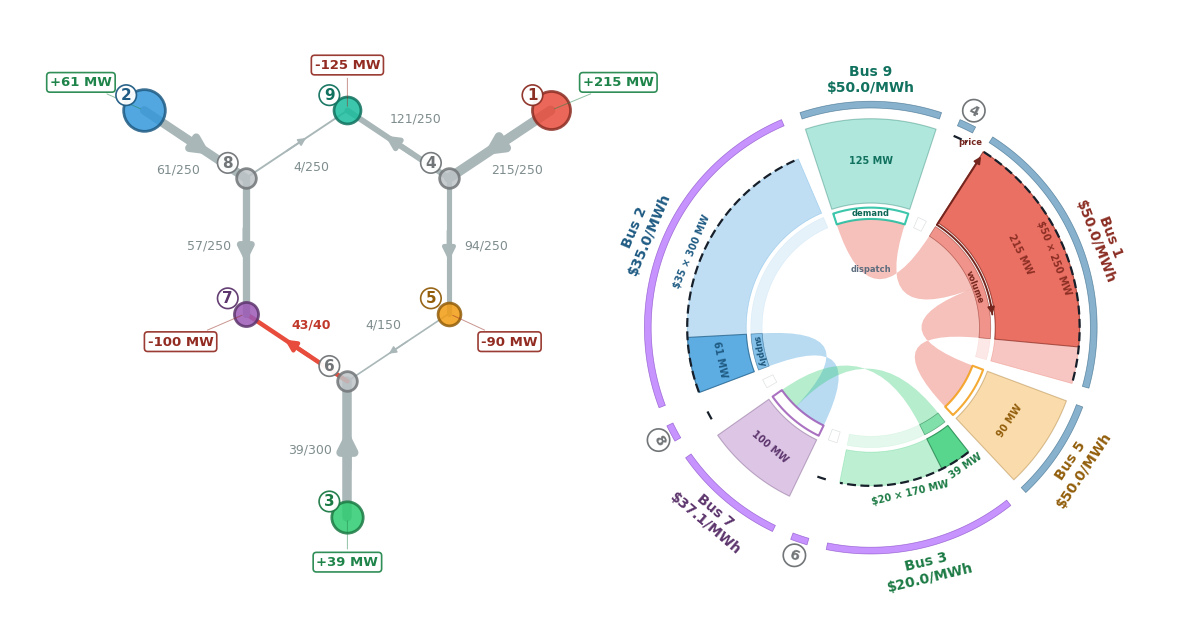

Nodal prices, each bus priced by its own market ($/MWh):

,1,2,3,4,5,6,7,8,9
market,Market B,Market A,Market A,Market B,Market B,Market A,Market A,Market A,Market B
LMP,50.0,35.0,20.0,50.0,50.0,20.0,37.13,35.0,50.0


dispatch, Market A (MW):

{'gen_0': 60.6, 'gen_1': 39.4}

Binding lines, Market A:

,flow (MW),rating (MW),shadow price ($/MWh)
line_4 (6-7),40.0,40.0,-20.1


... (3 outputs left out)

Production cost and load payment, eq. (4):

,generation (MW),load (MW),production cost ($/h),load pays ($/h)
Market A,100.0,100.0,2908.5,3712.6
Market B,215.0,215.0,10750.0,10750.0
"two markets, total",315.0,315.0,13658.5,14462.6
"one market, same knobs",315.0,315.0,8941.0,9745.1


Each market's own flow and their sum, eq. (5) (MW):

,from,to,F[Market A],F[Market B],F_phys,rating,loading_%,overload
line,,,,,,,,
line_0,1,4,0.0,215.0,215.0,250.0,86.0,False
line_1,4,5,0.6,93.4,94.0,250.0,38.0,False
line_2,5,6,0.6,3.4,4.0,150.0,3.0,False
line_3,3,6,39.4,-0.0,39.4,300.0,13.0,False
line_4,6,7,40.0,3.4,43.4,40.0,109.0,True
line_5,7,8,-60.0,3.4,-56.6,250.0,23.0,False
line_6,8,2,-60.6,0.0,-60.6,250.0,24.0,False
line_7,8,9,0.6,3.4,4.0,250.0,2.0,False
line_8,9,4,0.6,-121.6,-121.0,250.0,48.0,False


In [10]:
NET_S = wm.build_network(SB_RATINGS)
PT_S = compute_ptdf(NET_S, slack_bus="1")
FP_S = fpmod.make(PT_S, MARKETS, MARKET_COLORS)
RUNS = {}
for m, buses in MARKETS.items():
    eng = wm.make_engine(m, buses, gen_fleet=SB_FLEET, loads=SB_LOADS, activated=ACTIVATED[m])
    RUNS[m] = (eng, solve_engine_dispatch(PT_S, eng))
HOST = {b: m for m, buses in MARKETS.items() for b in buses}
PRICES_S = {b: RUNS[HOST[b]][1].lmp[b] for b in PT_S.buses}   # each bus at its own market's price

# each market's own clearing, the other market grayed
for m, (eng, res) in RUNS.items():
    figure(NET_S, PT_S, FP_S, eng, res, highlight=m, prices=PRICES_S)

# the two clearings together: the flow of (5), red where it exceeds the rating
FLOWS_S = physical_flows(PT_S, [res for _, res in RUNS.values()], exo_physical=False)
sup_s: dict = {}
dem_s: dict = {}
chords: list = []
for eng, res in RUNS.values():
    s, d = to_supply_demand(eng, res)
    sup_s.update(s)
    dem_s.update(d)
    chords += compute_ptdf_flows(NET_S, s, d)   # each market's own gen-to-load chords
fig, _ = plot_combined_letter(
    NET_S, sup_s, dem_s, bus_colors=dict(BUS_COLORS), bus_lmps=PRICES_S,
    bus_net_mw={b: float(sum(r.injection[PT_S.bus_idx[b]] for _, r in RUNS.values()))
                for b in PT_S.buses},
    network_show_lmp=False, line_flows={m: float(FLOWS_S.loc[m, "F_phys"]) for m in PT_S.lines},
    line_widths=susceptance_widths(PT_S), line_colors=FP_S.line_colors(PT_S),
    constrained_lines=list(FLOWS_S.index[FLOWS_S["overload"]]), flows=chords, lmp_line=True,
    bus_groups=FP_S.groups(PT_S), group_colors=dict(FP_S.colors), show_group_labels=False,
    all_buses=PT_S.buses, sector_order=RING_ORDER, bus_coords=COORDS, center_bus=CENTER_BUS,
    annotate_roles=True, axis_key=True, title_left="", title_right="")
sv.strip(fig)
plt.show()

print("Nodal prices, each bus priced by its own market ($/MWh):")
display(pd.DataFrame({"market": HOST, "LMP": {b: round(v, 2) for b, v in PRICES_S.items()}}
                     ).T[[b for b in PT_S.buses if b in HOST]])
for m, (_eng, res) in RUNS.items():
    print(f"dispatch, {m} (MW):", {g: round(x, 1) for g, x in res.dispatch.items()})
    show_binding(PT_S, res, f"Binding lines, {m}")

_n1, _p1, ENG_1, RES_1 = clear(SB_RATINGS, fleet=SB_FLEET, loads=SB_LOADS)
SB_TABLE = pd.DataFrame({m: cost_and_payment(eng, res, MARKETS[m])
                         for m, (eng, res) in RUNS.items()}).T
SB_TABLE.loc["two markets, total"] = SB_TABLE.sum()
SB_TABLE.loc["one market, same knobs"] = pd.Series(
    cost_and_payment(ENG_1, RES_1, [str(b) for b in _p1.buses]))
print("Production cost and load payment, eq. (4):")
display(SB_TABLE.round(1))
print("Each market's own flow and their sum, eq. (5) (MW):")
display(FLOWS_S.round(1))

As configured, Market A serves its 100 MW at bus 7 from its own units and binds line 6-7 at 40 MW with Example 2's shadow price, $-\$20.10$/MWh. Its \$20 unit at bus 3 runs 39.4 MW and its \$35 unit at bus 2 runs 60.6 MW, for a production cost of \$2,908.5/h. Market B serves its 215 MW from its \$50 unit at bus 1, for \$10,750/h, and prices every bus of its footprint at \$50/MWh. The two markets together cost \$13,658.5/h, \$4,717.5/h more than one market on the same knobs. Market B's own flow puts 3.4 MW on line 6-7, a line Market B does not activate, so the flow of (5) on line 6-7 is 43.4 MW against its 40 MW rating. Neither market's clearing holds that sum within the rating.

## What this notebook leaves out

Interface limits, self-schedules, bids, scheduling limits, flowgates, HVDC links, load shed, the settlement ledgers and the allocation of congestion revenue are all left out of this notebook. `sandbox.ipynb` carries each of them on the same case and engine. The workshop notebooks work through the examples of the seams workshops.